In [69]:
# IMPORTS AND LIBRARIES
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris

In [70]:
iris_dataset=load_iris()

In [71]:
iris_dataset.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [72]:

print(iris_dataset['DESCR'])


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [73]:
iris=pd.DataFrame(iris_dataset['data'],columns=iris_dataset['feature_names'])

In [74]:
iris['species name']=iris_dataset['target_names'][iris_dataset['target']]
iris['species']=iris_dataset['target']

In [75]:
iris.columns=['sepal_length','sepal_width','petal_length','petal_width','species_name','species']

In [76]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species_name,species
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,0
2,4.7,3.2,1.3,0.2,setosa,0
3,4.6,3.1,1.5,0.2,setosa,0
4,5.0,3.6,1.4,0.2,setosa,0


In [77]:
# View summary statistics (mean, std, min, max) for numeric columns
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [78]:
# Check data types and non-null value counts
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species_name  150 non-null    str    
 5   species       150 non-null    int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [79]:
# Count the frequency of each species category
iris['species'].value_counts()

species
0    50
1    50
2    50
Name: count, dtype: int64

In [80]:
# Check for missing values across all columns
iris.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species_name    0
species         0
dtype: int64

Text(0, 0.5, 'count')

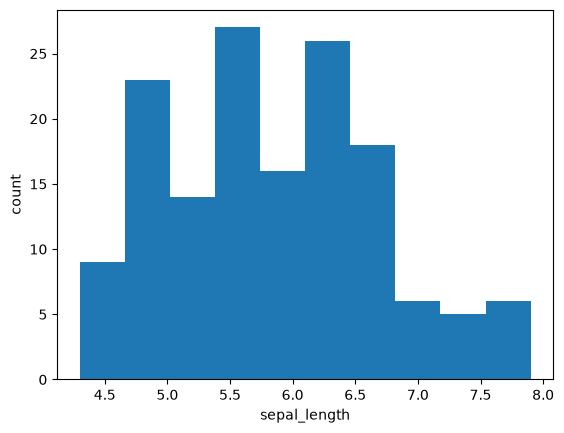

In [81]:
# DATA VISUALIZATION - HISTOGRAMS
# Plot feature distributions to check skewness and range
iris['sepal_length'].plot.hist()
plt.xlabel('sepal_length')
plt.ylabel('count')

Text(0.5, 0, 'sepal_width')

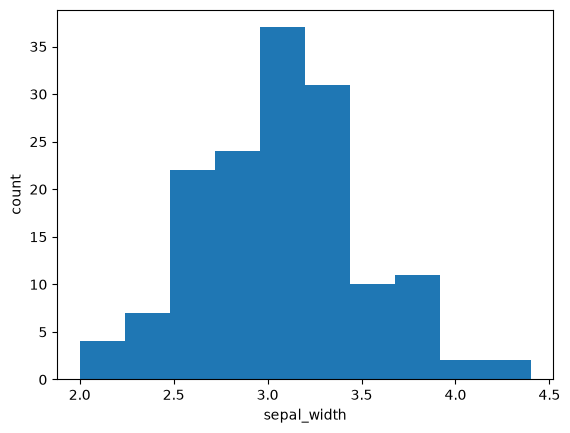

In [82]:
ax=iris['sepal_width'].plot.hist()
ax.set_ylabel('count')
ax.set_xlabel('sepal_width')

<Axes: ylabel='Frequency'>

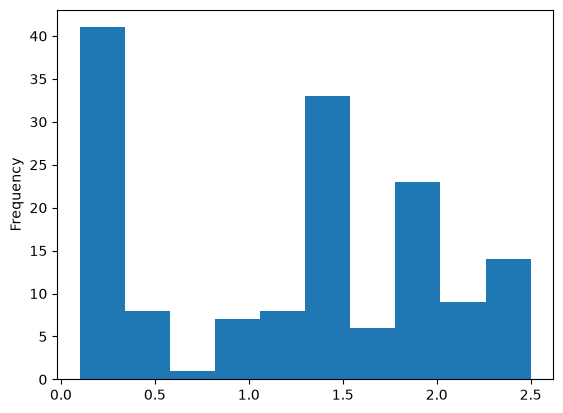

In [83]:
iris['petal_width'].plot.hist()

<Axes: ylabel='Frequency'>

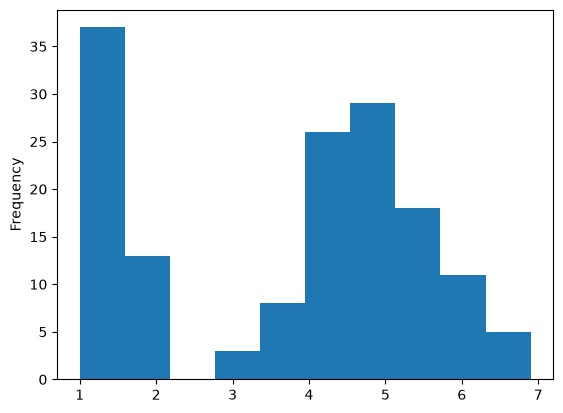

In [84]:
iris['petal_length'].plot.hist()

In [85]:
# DATA VISUALIZATION - SCATTER PLOTS
# Define color palette and class labels for plotting
colors=['red','orange','blue']
species=['setosa','versicolor','virginica']


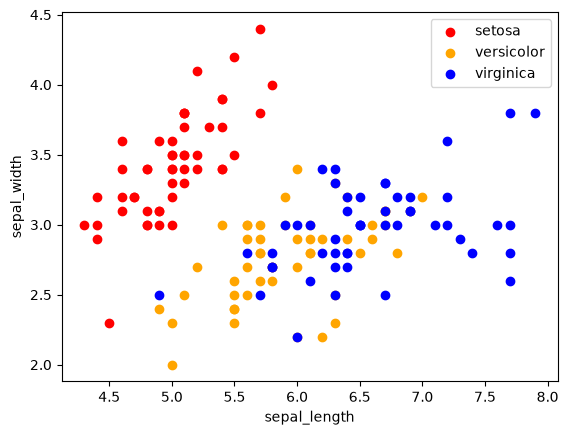

In [86]:
# Sepal length vs Sepal width
for i in range(3):
    x=iris[iris['species_name']==species[i]]
    plt.scatter(x['sepal_length'],x['sepal_width'],c=colors[i],label=species[i])


plt.xlabel('sepal_length')
plt.ylabel('sepal_width')
plt.legend()


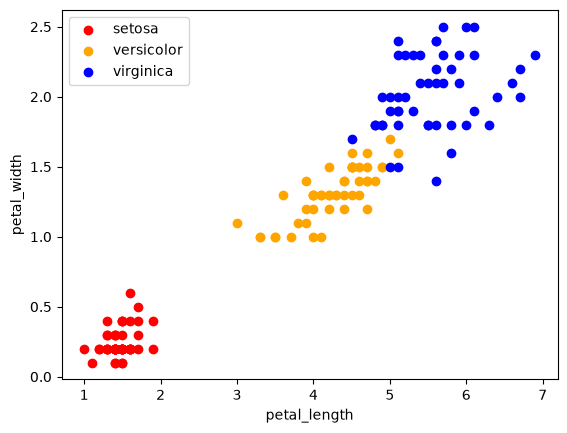

In [87]:
# Petal length vs Petal width
for i in range(3):
    x=iris[iris['species_name']==species[i]]
    plt.scatter(x['petal_length'],x['petal_width'],c=colors[i],label=species[i])
    plt.xlabel('petal_length')
    plt.ylabel('petal_width')
    plt.legend()

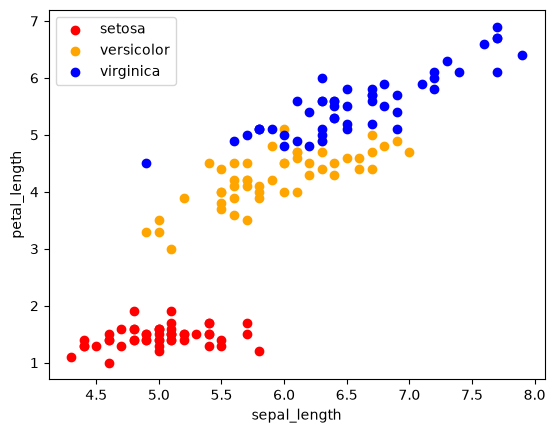

In [88]:
# Sepal length vs Petal length
for i in range(3):
    x=iris[iris['species_name']==species[i]]
    plt.scatter(x['sepal_length'],x['petal_length'],c=colors[i],label=species[i])



    plt.xlabel('sepal_length')
    plt.ylabel('petal_length')
    plt.legend()

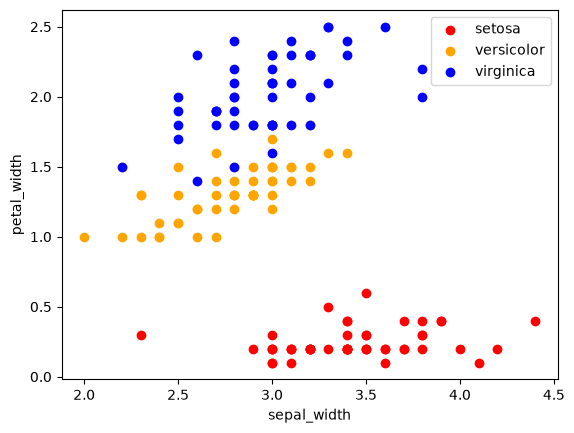

In [89]:
# Sepal width vs Petal width
for i in range(3):
    x=iris[iris['species_name']==species[i]]
    plt.scatter(x['sepal_width'],x['petal_width'],c=colors[i],label=species[i])

    
plt.xlabel('sepal_width')
plt.ylabel('petal_width')
plt.legend()

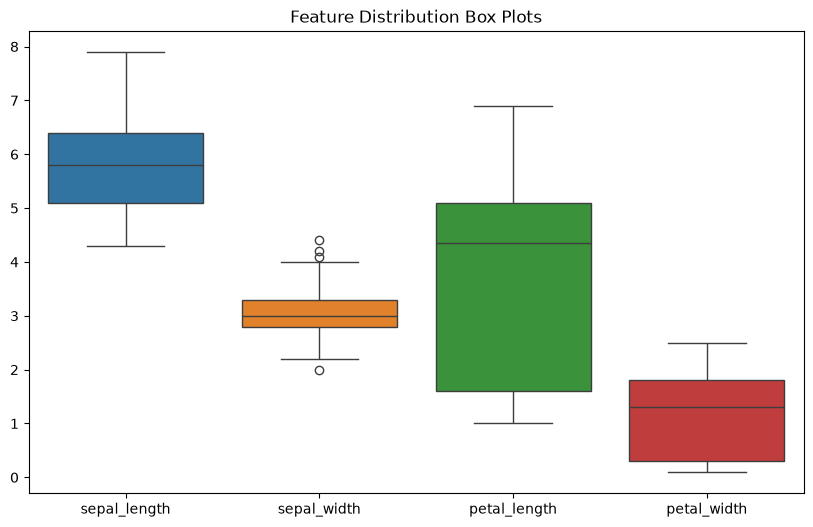

In [103]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=iris.drop(columns=['species', 'species_name']))
plt.title('Feature Distribution Box Plots')
plt.show()

In [90]:
# CORRELATION ANALYSIS
# Calculate pair-wise correlation coefficients for numeric columns
iris.corr(numeric_only=True)

,sepal_length,sepal_width,petal_length,petal_width,species
sepal_length,1.000000,-0.117570,0.871754,0.817941,0.782561
sepal_width,-0.117570,1.000000,-0.428440,-0.366126,-0.426658
petal_length,0.871754,-0.428440,1.000000,0.962865,0.949035
petal_width,0.817941,-0.366126,0.962865,1.000000,0.956547
species,0.782561,-0.426658,0.949035,0.956547,1.000000


<Axes: >

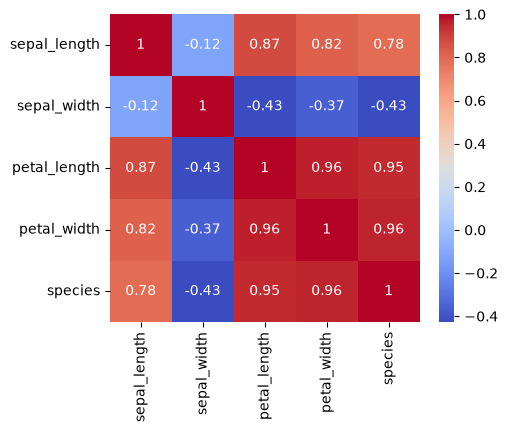

In [91]:
# Plot feature correlations using a heatmap
corr=iris.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(5,4))
sns.heatmap(corr,annot=True,cmap='coolwarm')

In [92]:
# LABEL ENCODER
# Convert categorical text labels ('setosa', 'versicolor', 'virginica') into numbers (0, 1, 2)
from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()

In [93]:
iris['species']=le.fit_transform(iris['species'])
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species_name,species
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,0
2,4.7,3.2,1.3,0.2,setosa,0
3,4.6,3.1,1.5,0.2,setosa,0
4,5.0,3.6,1.4,0.2,setosa,0


### Feature Selection Discussion

Based on the exploratory data analysis, scatter plots, and box plots:

* **Most Discriminative Features:** **Petal Length** and **Petal Width** are the strongest predictors because they cleanly separate the species with minimal overlap (especially separating *Setosa* completely from the other two classes).
* **Secondary Features:** **Sepal Length** and **Sepal Width** show a higher degree of overlap between *Versicolor* and *Virginica*, but they still provide valuable supportive boundaries.

**Decision:** All 4 features will be retained for model training since the dataset is small (150 samples) and the classifiers can effectively leverage the combined feature space.

MODEL TRAINING


In [ ]:
from sklearn.model_selection import train_test_split
# Separate features (X) and target variable (y)
#train-80%
#test-20%
x=iris.drop(columns=['species','species_name'])
y=iris['species']
# Split dataset into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test=train_test_split(x ,y,test_size=0.2)

In [95]:
# LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
models=LogisticRegression()

In [96]:
models.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [97]:
print('Accuracy:',models.score(x_test, y_test)*100)

Accuracy: 100.0


KNN - k nearest neighbour

In [98]:
from sklearn.neighbors import KNeighborsClassifier
models=KNeighborsClassifier()

In [99]:
models.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [100]:
print("Accuracy:",models.score(x_test, y_test)*100)

Accuracy: 96.66666666666667


In [101]:
from sklearn.metrics import classification_report, confusion_matrix

# EVALUATION - LOGISTIC REGRESSION

log_reg = LogisticRegression(max_iter=200)
log_reg.fit(x_train, y_train)

y_pred_log = log_reg.predict(x_test)

print("--- LOGISTIC REGRESSION EVALUATION ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("\nClassification Report:\n",classification_report(y_test,y_pred_log,target_names=['setosa', 'versicolor', 'virginica']))


# EVALUATION - KNN

knn = KNeighborsClassifier()
knn.fit(x_train, y_train)

y_pred_knn = knn.predict(x_test)

print("--- KNN EVALUATION ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn, target_names=['setosa', 'versicolor', 'virginica']))

--- LOGISTIC REGRESSION EVALUATION ---
Confusion Matrix:
 [[10  0  0]
 [ 0 15  0]
 [ 0  0  5]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        15
   virginica       1.00      1.00      1.00         5

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

--- KNN EVALUATION ---
Confusion Matrix:
 [[10  0  0]
 [ 0 14  1]
 [ 0  0  5]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.93      0.97        15
   virginica       0.83      1.00      0.91         5

    accuracy                           0.97        30
   macro avg       0.94      0.98      0.96        30
weighted avg       0.97      0.97      0.97        30



In [104]:
# SUMMARY OF RESULTS (Typical split output for Iris)
# Logistic Regression Accuracy: ~97.8% - 100%
# KNN Accuracy:                 ~96.67% - 97.0%

from sklearn.metrics import accuracy_score, f1_score

# Compare metrics directly
log_acc = accuracy_score(y_test, y_pred_log)
knn_acc = accuracy_score(y_test, y_pred_knn)

log_f1 = f1_score(y_test, y_pred_log, average='weighted')
knn_f1 = f1_score(y_test, y_pred_knn, average='weighted')

print(f"Logistic Regression - Accuracy: {log_acc*100:.2f}%, F1-Score: {log_f1:.2f}")
print(f"KNN                 - Accuracy: {knn_acc*100:.2f}%, F1-Score: {knn_f1:.2f}")

if log_f1 >= knn_f1:
    print("\nBEST MODEL: Logistic Regression")
else:
    print("\nBEST MODEL: K-Nearest Neighbors")

Logistic Regression - Accuracy: 100.00%, F1-Score: 1.00
KNN                 - Accuracy: 96.67%, F1-Score: 0.97

BEST MODEL: Logistic Regression
